# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [17]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [18]:
# Load the cleaned data
df = pd.read_csv("data/cleaned_aviation_data.csv")

# Check that the data loaded correctly
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (16370, 36)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.Passengers,Serious.Fatal.Injuries,Serious.Fatal.Injury.Rate,Aircraft.Destroyed,Make_Model
0,20001214X42478,Incident,LAX83IA149A,1983-03-18,"LOS ANGELES, CA",United States,NaN,NaN,LAX,LOS ANGELES INTL,...,588.0,VMC,Taxi,Probable Cause,04-12-2014,588.0,0.0,0.0,0,BOEING 747
1,20001214X42331,Accident,ATL83FA140,1983-03-20,"CROSSVILLE, TN",United States,NaN,NaN,NaN,NaN,...,0.0,IMC,Cruise,Probable Cause,02-05-2011,2.0,2.0,1.0,1,PIPER PA-28-140
2,20001214X45013,Incident,CHI84IA041,1983-11-08,"CHICAGO, IL",United States,NaN,NaN,ORD,O'HARE,...,100.0,VMC,Taxi,Probable Cause,11-06-2018,100.0,0.0,0.0,0,BOEING 727-200
3,20001214X45188,Accident,NYC84LA028,1983-11-13,"MARTHA'S VINEYARD, MA",United States,NaN,NaN,NaN,NaN,...,1.0,VMC,Climb,Probable Cause,05-05-2011,1.0,0.0,0.0,0,BEECH C35
4,20001214X45339,Accident,LAX84LA110,1983-12-22,"SANTA ROSA ISLAND, CA",United States,NaN,NaN,NaN,PRIVATE,...,1.0,VMC,Takeoff,Probable Cause,01-02-2016,1.0,0.0,0.0,0,CESSNA 180K


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [19]:
# Separate aircraft using a threshold of 20 passengers

small_planes = df[df["Total.Passengers"] <= 20].copy()
large_planes = df[df["Total.Passengers"] > 20].copy()

# Check the number of records in each group
print("Small airplane records:", small_planes.shape[0])
print("Large airplane records:", large_planes.shape[0])

# Check the passenger ranges
print("\nSmall airplane passenger range:")
print(small_planes["Total.Passengers"].min(),
      "to",
      small_planes["Total.Passengers"].max())

print("\nLarge airplane passenger range:")
print(large_planes["Total.Passengers"].min(),
      "to",
      large_planes["Total.Passengers"].max())

Small airplane records: 15946
Large airplane records: 424

Small airplane passenger range:
1.0 to 20.0

Large airplane passenger range:
21.0 to 588.0


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [21]:
# Calculate the mean serious/fatal injury rate for each make

small_make_rates = (
    small_planes.groupby("Make")["Serious.Fatal.Injury.Rate"]
    .mean()
    .sort_values()
    .head(15)
)

large_make_rates = (
    large_planes.groupby("Make")["Serious.Fatal.Injury.Rate"]
    .mean()
    .sort_values()
    .head(15)
)

# Display the results
print("15 small aircraft makes with the lowest mean injury rates:")
print(small_make_rates)

print("\n15 large aircraft makes with the lowest mean injury rates:")
print(large_make_rates)

15 small aircraft makes with the lowest mean injury rates:
Make
MCDONNELL DOUGLAS                 0.127551
MAULE                             0.164806
BOEING                            0.164869
AVIAT AIRCRAFT INC                0.166667
GRUMMAN ACFT ENG COR-SCHWEIZER    0.206897
AYRES                             0.215686
STINSON                           0.216408
AVIAT                             0.221429
DIAMOND AIRCRAFT IND INC          0.222973
BELLANCA                          0.223624
ROCKWELL INTERNATIONAL            0.223684
DEHAVILLAND                       0.225754
AERONCA                           0.225833
CHAMPION                          0.262208
CESSNA                            0.263764
Name: Serious.Fatal.Injury.Rate, dtype: float64

15 large aircraft makes with the lowest mean injury rates:
Make
DEHAVILLAND          0.000000
MCDONNELL DOUGLAS    0.008176
BOEING               0.101140
EMBRAER              0.104508
AIRBUS               0.185202
DE HAVILLAND         0.21179

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

Small aircraft make sample sizes:
Make
MCDONNELL DOUGLAS                   21
MAULE                              215
BOEING                             204
AVIAT AIRCRAFT INC                  75
GRUMMAN ACFT ENG COR-SCHWEIZER      58
AYRES                               51
STINSON                            129
AVIAT                               70
DIAMOND AIRCRAFT IND INC            74
BELLANCA                           218
ROCKWELL INTERNATIONAL              57
DEHAVILLAND                         91
AERONCA                            200
CHAMPION                           157
CESSNA                            6972
Name: count, dtype: int64

Large aircraft make sample sizes:
Make
DEHAVILLAND            1
MCDONNELL DOUGLAS     36
BOEING               282
EMBRAER               45
AIRBUS                53
DE HAVILLAND           6
BEECH                  1
Name: count, dtype: int64


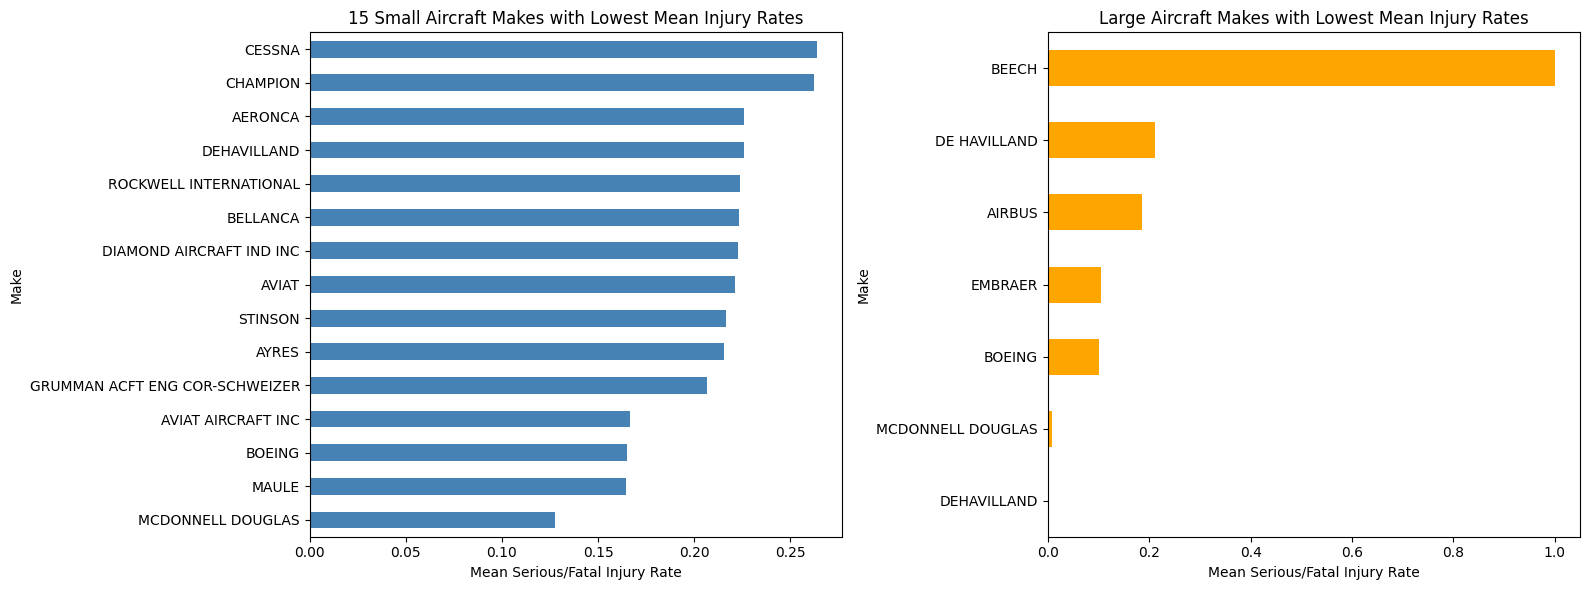

In [22]:
# Check the number of records for each selected make
small_make_counts = small_planes["Make"].value_counts()
large_make_counts = large_planes["Make"].value_counts()

print("Small aircraft make sample sizes:")
print(small_make_counts.loc[small_make_rates.index])

print("\nLarge aircraft make sample sizes:")
print(large_make_counts.loc[large_make_rates.index])

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

small_make_rates.sort_values().plot(
    kind="barh",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("15 Small Aircraft Makes with Lowest Mean Injury Rates")
axes[0].set_xlabel("Mean Serious/Fatal Injury Rate")
axes[0].set_ylabel("Make")

large_make_rates.sort_values().plot(
    kind="barh",
    ax=axes[1],
    color="orange"
)

axes[1].set_title("Large Aircraft Makes with Lowest Mean Injury Rates")
axes[1].set_xlabel("Mean Serious/Fatal Injury Rate")
axes[1].set_ylabel("Make")

plt.tight_layout()
plt.show()

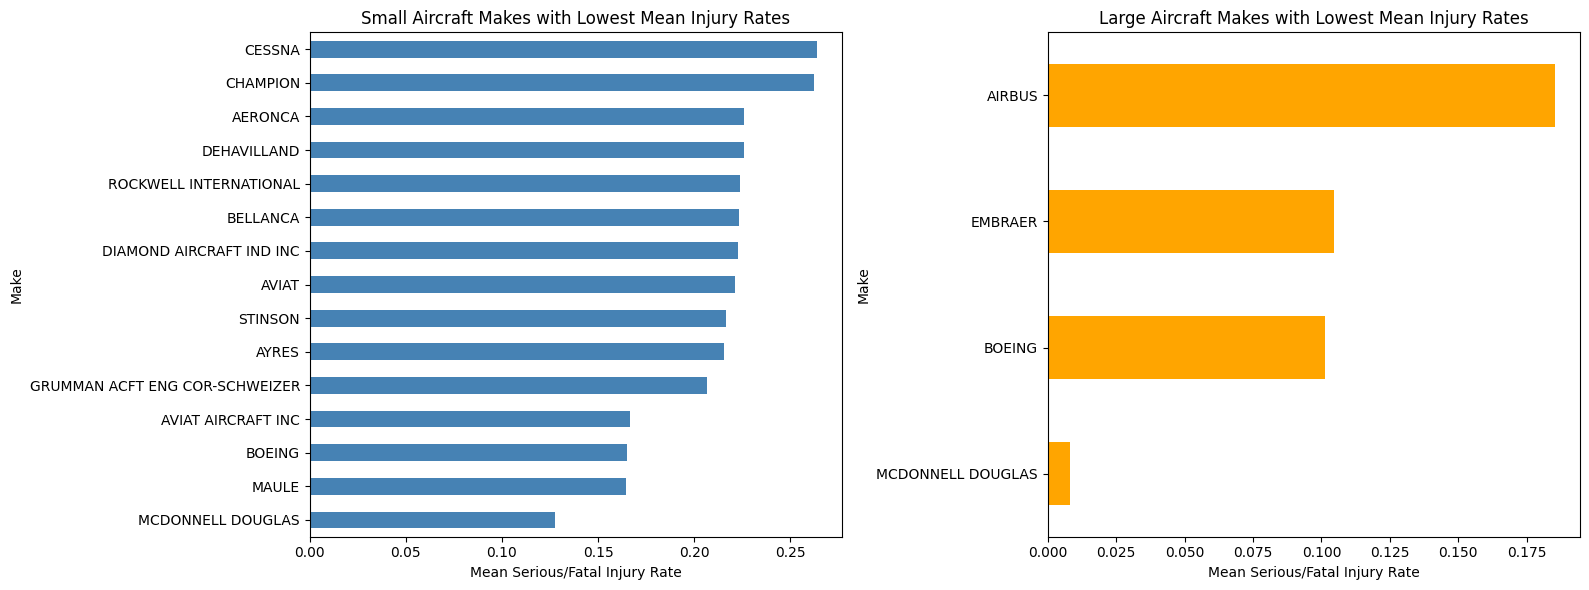

Small aircraft makes:
                                Mean Injury Rate  Sample Size
Make                                                         
MCDONNELL DOUGLAS                       0.127551           21
MAULE                                   0.164806          215
BOEING                                  0.164869          204
AVIAT AIRCRAFT INC                      0.166667           75
GRUMMAN ACFT ENG COR-SCHWEIZER          0.206897           58
AYRES                                   0.215686           51
STINSON                                 0.216408          129
AVIAT                                   0.221429           70
DIAMOND AIRCRAFT IND INC                0.222973           74
BELLANCA                                0.223624          218
ROCKWELL INTERNATIONAL                  0.223684           57
DEHAVILLAND                             0.225754           91
AERONCA                                 0.225833          200
CHAMPION                                0.262208

In [23]:
# Keep aircraft makes with at least 10 records

small_make_counts = small_planes["Make"].value_counts()
large_make_counts = large_planes["Make"].value_counts()

valid_small_makes = small_make_counts[small_make_counts >= 10].index
valid_large_makes = large_make_counts[large_make_counts >= 10].index

# Calculate the lowest mean injury rates after applying the sample-size rule
small_make_rates = (
    small_planes[small_planes["Make"].isin(valid_small_makes)]
    .groupby("Make")["Serious.Fatal.Injury.Rate"]
    .mean()
    .sort_values()
    .head(15)
)

large_make_rates = (
    large_planes[large_planes["Make"].isin(valid_large_makes)]
    .groupby("Make")["Serious.Fatal.Injury.Rate"]
    .mean()
    .sort_values()
    .head(15)
)

# Plot the results side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

small_make_rates.sort_values().plot(
    kind="barh",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Small Aircraft Makes with Lowest Mean Injury Rates")
axes[0].set_xlabel("Mean Serious/Fatal Injury Rate")
axes[0].set_ylabel("Make")

large_make_rates.sort_values().plot(
    kind="barh",
    ax=axes[1],
    color="orange"
)

axes[1].set_title("Large Aircraft Makes with Lowest Mean Injury Rates")
axes[1].set_xlabel("Mean Serious/Fatal Injury Rate")
axes[1].set_ylabel("Make")

plt.tight_layout()
plt.show()

# Display the final results and sample sizes
print("Small aircraft makes:")
print(pd.DataFrame({
    "Mean Injury Rate": small_make_rates,
    "Sample Size": small_make_counts.loc[small_make_rates.index]
}))

print("\nLarge aircraft makes:")
print(pd.DataFrame({
    "Mean Injury Rate": large_make_rates,
    "Sample Size": large_make_counts.loc[large_make_rates.index]
}))

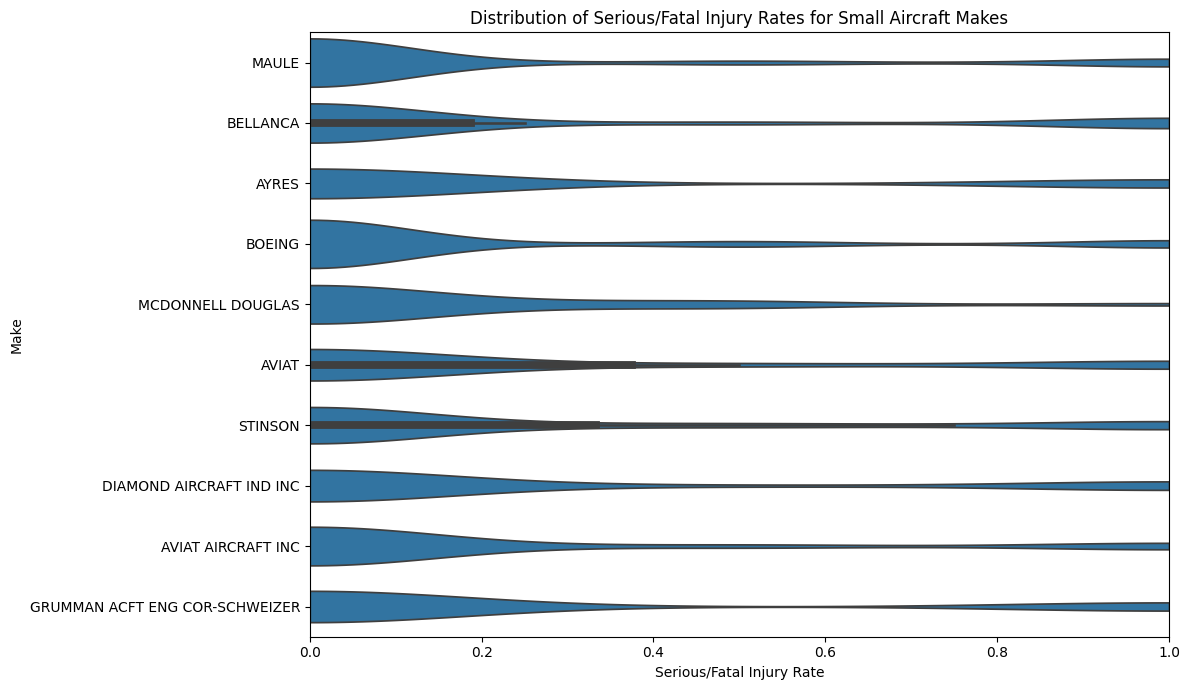

In [24]:
# Select the 10 small aircraft makes with the lowest mean injury rates
lowest_10_small_makes = small_make_rates.head(10).index

# Filter records for those makes
small_plot_data = small_planes[
    small_planes["Make"].isin(lowest_10_small_makes)
]

# Create the violin plot
plt.figure(figsize=(12, 7))

sns.violinplot(
    data=small_plot_data,
    x="Serious.Fatal.Injury.Rate",
    y="Make",
    cut=0
)

plt.xlim(0, 1)
plt.title("Distribution of Serious/Fatal Injury Rates for Small Aircraft Makes")
plt.xlabel("Serious/Fatal Injury Rate")
plt.ylabel("Make")
plt.tight_layout()
plt.show()

The violin plot shows that serious/fatal injury rates vary within each small-aircraft make. Most observations are concentrated near zero, indicating that many recorded accidents did not result in serious or fatal injuries. However, several makes have distributions extending toward 1.0, meaning some accidents resulted in all recorded persons being seriously or fatally injured. Therefore, recommendations should consider both the average injury rate, the distribution of outcomes, and the number of accident records available for each make.

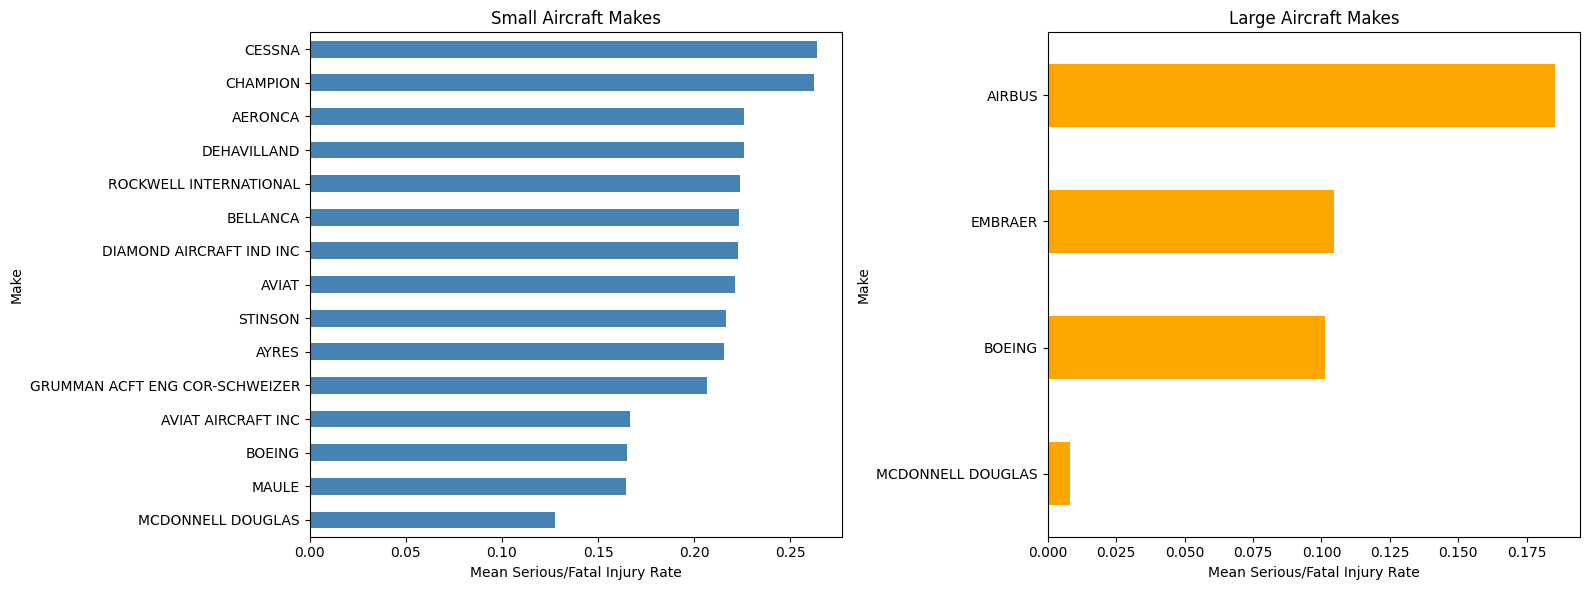

In [25]:
# Plot mean serious/fatal injury rates side by side

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

small_make_rates.sort_values().plot(
    kind="barh",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Small Aircraft Makes")
axes[0].set_xlabel("Mean Serious/Fatal Injury Rate")
axes[0].set_ylabel("Make")

large_make_rates.sort_values().plot(
    kind="barh",
    ax=axes[1],
    color="orange"
)

axes[1].set_title("Large Aircraft Makes")
axes[1].set_xlabel("Mean Serious/Fatal Injury Rate")
axes[1].set_ylabel("Make")

plt.tight_layout()
plt.show()

The results show differences in the mean serious/fatal injury rate between aircraft makes. Among the selected small-aircraft makes, McDonnell Douglas recorded the lowest mean rate, followed by Maule and Boeing. For larger aircraft, McDonnell Douglas recorded the lowest mean rate among the makes displayed, followed by Boeing and Embraer. Airbus had the highest mean rate among the four large-aircraft makes shown. These findings are based on accident records rather than the total number of aircraft in operation, so they show injury outcomes when an accident occurred and should not be interpreted as overall accident probabilities.

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

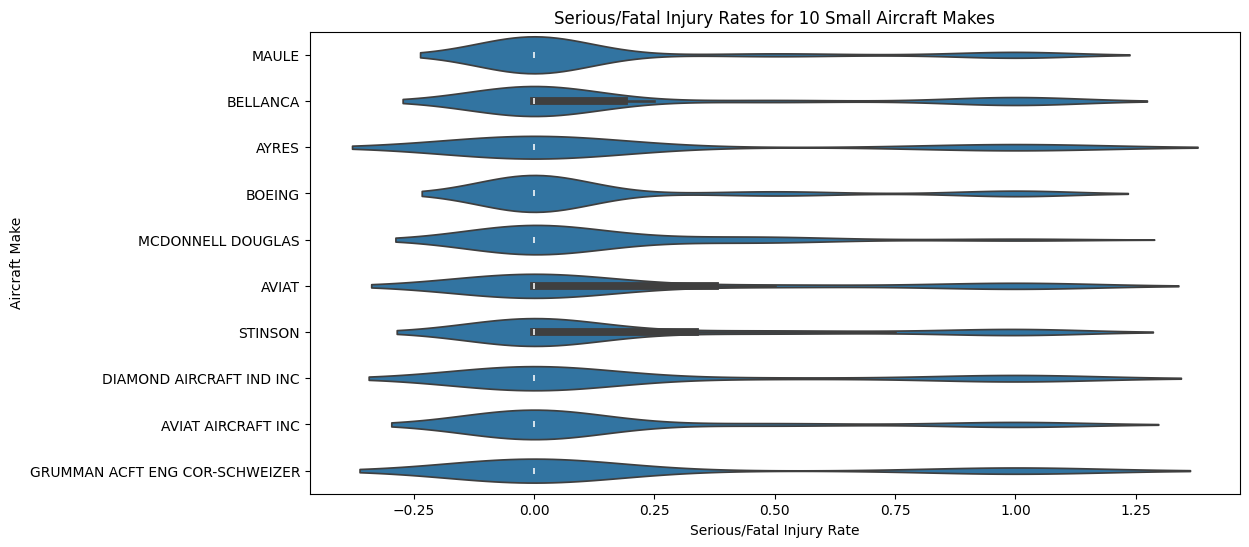

In [26]:
# Select the 10 small aircraft makes with the lowest mean injury rates
small_top10 = small_make_rates.head(10).index

# Filter the data to these 10 makes
small_plot_data = small_planes[
    small_planes["Make"].isin(small_top10)
]

# Create the violin plot
plt.figure(figsize=(12, 6))

sns.violinplot(
    data=small_plot_data,
    x="Serious.Fatal.Injury.Rate",
    y="Make"
)

plt.title("Serious/Fatal Injury Rates for 10 Small Aircraft Makes")
plt.xlabel("Serious/Fatal Injury Rate")
plt.ylabel("Aircraft Make")

plt.show()

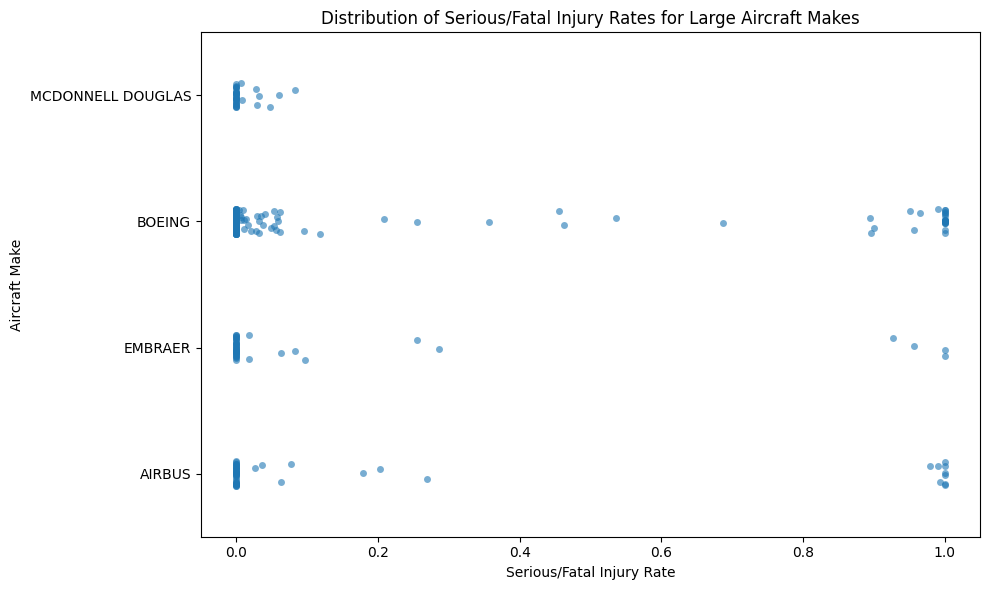

,Mean_Injury_Rate,Sample_Size
Make,,
MCDONNELL DOUGLAS,0.008176,36
BOEING,0.101140,282
EMBRAER,0.104508,45
AIRBUS,0.185202,53


In [27]:
# Select large aircraft makes with at least 10 records
large_make_counts = large_planes["Make"].value_counts()
valid_large_makes = large_make_counts[large_make_counts >= 10].index

# Calculate mean injury rate and select up to 10 lowest
lowest_large_makes = (
    large_planes[large_planes["Make"].isin(valid_large_makes)]
    .groupby("Make")["Serious.Fatal.Injury.Rate"]
    .mean()
    .sort_values()
    .head(10)
    .index
)

# Filter the data for the selected makes
large_stripplot_data = large_planes[
    large_planes["Make"].isin(lowest_large_makes)
]

# Create the stripplot
plt.figure(figsize=(10, 6))

sns.stripplot(
    data=large_stripplot_data,
    x="Serious.Fatal.Injury.Rate",
    y="Make",
    order=lowest_large_makes,
    jitter=True,
    alpha=0.6
)

plt.title("Distribution of Serious/Fatal Injury Rates for Large Aircraft Makes")
plt.xlabel("Serious/Fatal Injury Rate")
plt.ylabel("Aircraft Make")

plt.tight_layout()
plt.show()

# Display mean rates and sample sizes
large_make_summary = (
    large_stripplot_data.groupby("Make")
    .agg(
        Mean_Injury_Rate=("Serious.Fatal.Injury.Rate", "mean"),
        Sample_Size=("Make", "size")
    )
    .sort_values("Mean_Injury_Rate")
)

large_make_summary

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

Small aircraft makes with the lowest destruction rates:
Make
LUSCOMBE                          0.014388
GRUMMAN ACFT ENG COR-SCHWEIZER    0.017241
STINSON                           0.023256
TAYLORCRAFT                       0.032258
AERONCA                           0.035000
ERCOUPE                           0.038462
AMERICAN CHAMPION AIRCRAFT        0.039216
AVIAT AIRCRAFT INC                0.040000
MAULE                             0.041860
DEHAVILLAND                       0.043956
BELLANCA                          0.050459
DIAMOND AIRCRAFT IND INC          0.054054
CHAMPION                          0.076433
CESSNA                            0.095955
AVIAT                             0.100000
Name: Aircraft.Destroyed, dtype: float64

Large aircraft makes with the lowest destruction rates:
Make
EMBRAER              0.088889
BOEING               0.095745
MCDONNELL DOUGLAS    0.111111
AIRBUS               0.169811
Name: Aircraft.Destroyed, dtype: float64


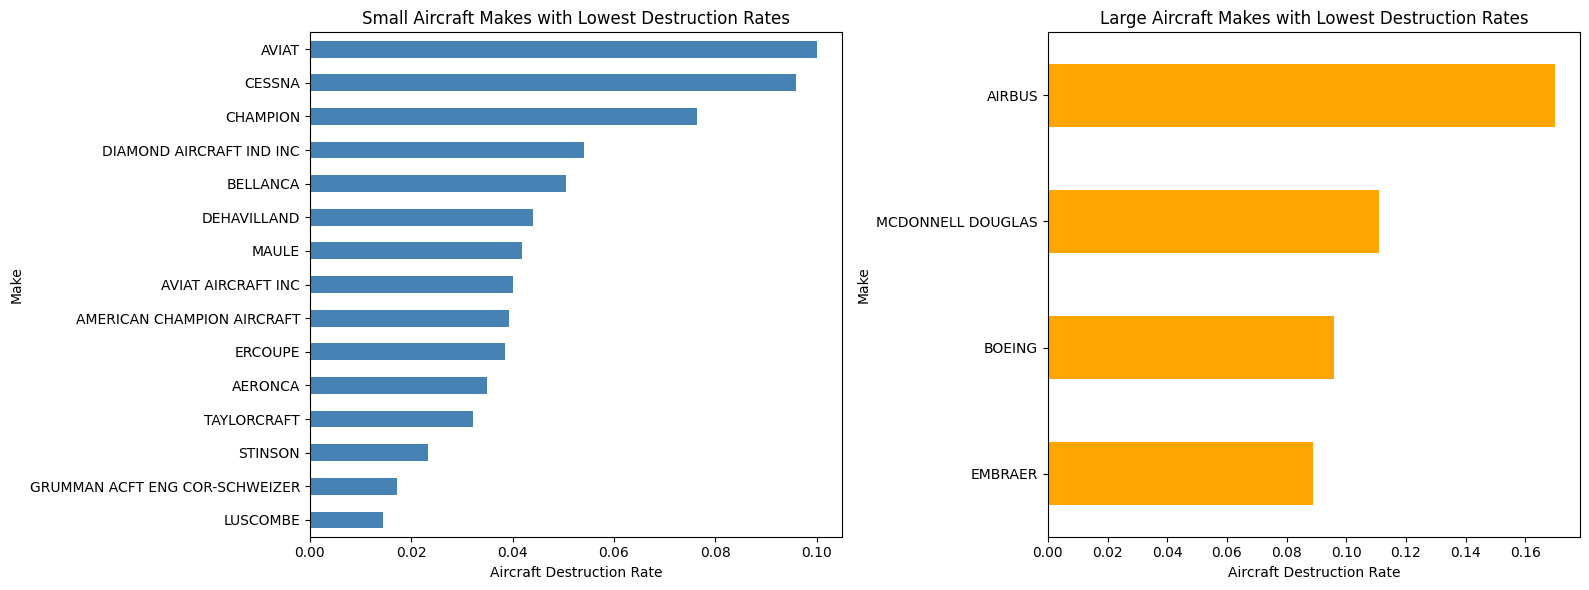

In [28]:
# Keep makes with at least 10 records
small_make_counts = small_planes["Make"].value_counts()
large_make_counts = large_planes["Make"].value_counts()

valid_small_makes = small_make_counts[small_make_counts >= 10].index
valid_large_makes = large_make_counts[large_make_counts >= 10].index

# Calculate the destruction rate by make
small_destruction_rates = (
    small_planes[small_planes["Make"].isin(valid_small_makes)]
    .groupby("Make")["Aircraft.Destroyed"]
    .mean()
    .sort_values()
    .head(15)
)

large_destruction_rates = (
    large_planes[large_planes["Make"].isin(valid_large_makes)]
    .groupby("Make")["Aircraft.Destroyed"]
    .mean()
    .sort_values()
    .head(15)
)

# Display the results
print("Small aircraft makes with the lowest destruction rates:")
print(small_destruction_rates)

print("\nLarge aircraft makes with the lowest destruction rates:")
print(large_destruction_rates)

# Plot the destruction rates side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

small_destruction_rates.sort_values().plot(
    kind="barh",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Small Aircraft Makes with Lowest Destruction Rates")
axes[0].set_xlabel("Aircraft Destruction Rate")
axes[0].set_ylabel("Make")

large_destruction_rates.sort_values().plot(
    kind="barh",
    ax=axes[1],
    color="orange"
)

axes[1].set_title("Large Aircraft Makes with Lowest Destruction Rates")
axes[1].set_xlabel("Aircraft Destruction Rate")
axes[1].set_ylabel("Make")

plt.tight_layout()
plt.show()

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

For larger aircraft, McDonnell Douglas shows the strongest result in this analysis, with the lowest mean serious/fatal injury rate of 0.0082 across 36 records. Its aircraft destruction rate is approximately 0.1111. Boeing is also worth considering because it has a mean serious/fatal injury rate of 0.1011 and a destruction rate of approximately 0.0957. Boeing also has the largest sample in the large-aircraft comparison with 282 records, which gives more support to the result. Embraer has a slightly higher mean injury rate of 0.1045, but recorded the lowest destruction rate among the large-aircraft makes at approximately 0.0889.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

                   Mean Injury Rate  Sample Size
Make                                            
MCDONNELL DOUGLAS          0.008176           36
BOEING                     0.101140          282
EMBRAER                    0.104508           45
AIRBUS                     0.185202           53


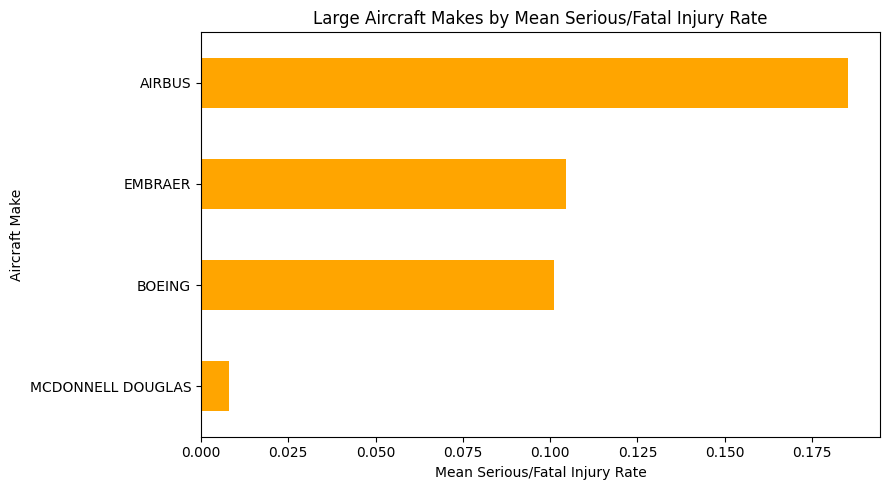

In [29]:
# LARGE PLANES ONLY

# Count the number of records for each large aircraft make
large_make_counts = large_planes["Make"].value_counts()

# Keep makes with at least 10 records
valid_large_makes = large_make_counts[large_make_counts >= 10].index

# Calculate mean serious/fatal injury rate
large_make_rates = (
    large_planes[large_planes["Make"].isin(valid_large_makes)]
    .groupby("Make")["Serious.Fatal.Injury.Rate"]
    .mean()
    .sort_values()
)

# Show results with sample sizes
large_make_summary = pd.DataFrame({
    "Mean Injury Rate": large_make_rates,
    "Sample Size": large_make_counts.loc[large_make_rates.index]
})

print(large_make_summary)

# Plot the results
plt.figure(figsize=(9, 5))

large_make_rates.plot(
    kind="barh",
    color="orange"
)

plt.title("Large Aircraft Makes by Mean Serious/Fatal Injury Rate")
plt.xlabel("Mean Serious/Fatal Injury Rate")
plt.ylabel("Aircraft Make")

plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

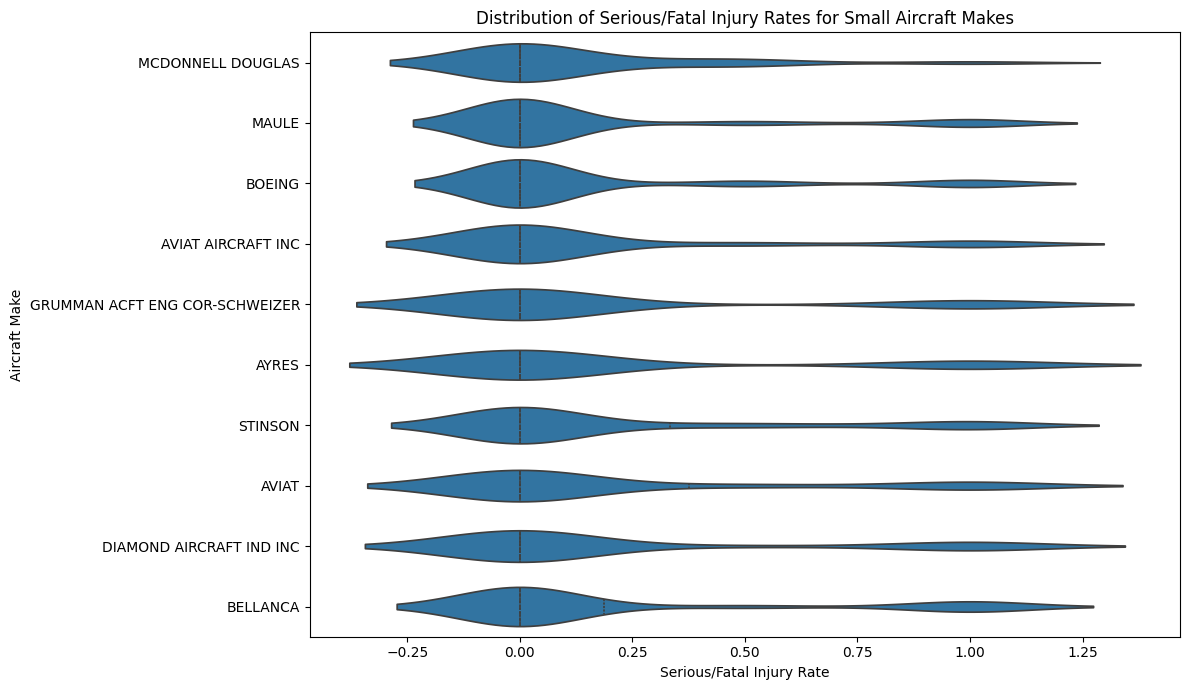

                                Mean_Injury_Rate  Sample_Size
Make                                                         
MCDONNELL DOUGLAS                       0.127551           21
MAULE                                   0.164806          215
BOEING                                  0.164869          204
AVIAT AIRCRAFT INC                      0.166667           75
GRUMMAN ACFT ENG COR-SCHWEIZER          0.206897           58
AYRES                                   0.215686           51
STINSON                                 0.216408          129
AVIAT                                   0.221429           70
DIAMOND AIRCRAFT IND INC                0.222973           74
BELLANCA                                0.223624          218


In [30]:
# Small aircraft makes with at least 10 records
small_make_counts = small_planes["Make"].value_counts()
valid_small_makes = small_make_counts[small_make_counts >= 10].index

# Find the 10 makes with the lowest mean serious/fatal injury rates
lowest_10_small_makes = (
    small_planes[small_planes["Make"].isin(valid_small_makes)]
    .groupby("Make")["Serious.Fatal.Injury.Rate"]
    .mean()
    .sort_values()
    .head(10)
    .index
)

# Filter the data to the selected 10 makes
small_plot_data = small_planes[
    small_planes["Make"].isin(lowest_10_small_makes)
]

# Create the violin plot
plt.figure(figsize=(12, 7))

sns.violinplot(
    data=small_plot_data,
    x="Serious.Fatal.Injury.Rate",
    y="Make",
    order=lowest_10_small_makes,
    inner="quartile"
)

plt.title("Distribution of Serious/Fatal Injury Rates for Small Aircraft Makes")
plt.xlabel("Serious/Fatal Injury Rate")
plt.ylabel("Aircraft Make")
plt.tight_layout()
plt.show()

# Display mean rates and sample sizes
small_summary = small_plot_data.groupby("Make").agg(
    Mean_Injury_Rate=("Serious.Fatal.Injury.Rate", "mean"),
    Sample_Size=("Make", "size")
).sort_values("Mean_Injury_Rate")

print(small_summary)

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

Among the qualifying large-aircraft makes, McDonnell Douglas recorded the lowest mean serious/fatal injury rate, followed by Boeing and Embraer. Airbus had the highest mean rate among the four qualifying large-aircraft makes. For small aircraft, the violin plot shows that the injury-rate distributions vary within each make, even where the mean rate is relatively low. Therefore, the mean rates should be considered together with the sample sizes and distributions before making final recommendations.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

Weather Condition:
                   Serious.Fatal.Injury.Rate  Aircraft.Destroyed
Weather.Condition                                               
IMC                                 0.663147            0.373223
Unknown                             0.557908            0.394118
VMC                                 0.236539            0.072427


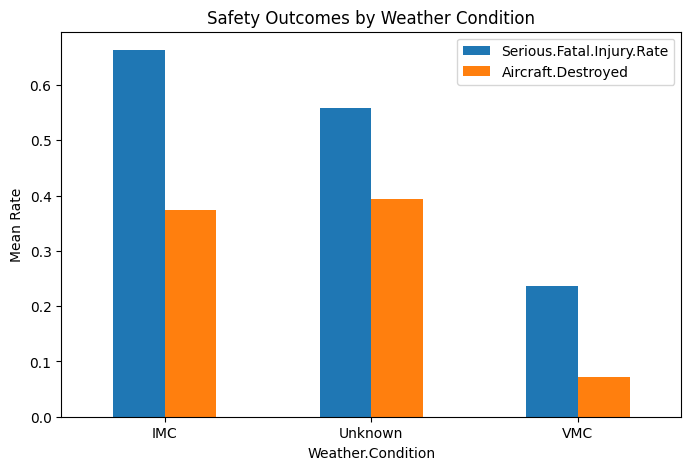

In [31]:
# Factor 1: Weather Condition
weather = df.groupby("Weather.Condition").agg({
    "Serious.Fatal.Injury.Rate": "mean",
    "Aircraft.Destroyed": "mean"
})

print("Weather Condition:")
print(weather)

weather.plot(kind="bar", figsize=(8, 5))
plt.title("Safety Outcomes by Weather Condition")
plt.ylabel("Mean Rate")
plt.xticks(rotation=0)
plt.show()

The results show differences in safety outcomes across weather conditions. Accidents occurring in IMC had the highest mean serious/fatal injury rate at 0.663 (66.3%), compared with 0.236 (23.6%) in VMC. The aircraft destruction rate was also higher under IMC at 37.3%, compared with 7.2% under VMC.

This suggests that accidents occurring under IMC were associated with more severe injury and aircraft damage outcomes in this dataset. However, the results show an association and do not necessarily mean that weather condition alone caused the more severe outcomes. The Unknown category was also relatively high, so it should be interpreted carefully.

Number of Engines:
                   Serious.Fatal.Injury.Rate  Aircraft.Destroyed
Number.of.Engines                                               
1.0                                 0.255848            0.077703
2.0                                 0.326520            0.175661
3.0                                 0.104824            0.062500
4.0                                 0.190379            0.166667


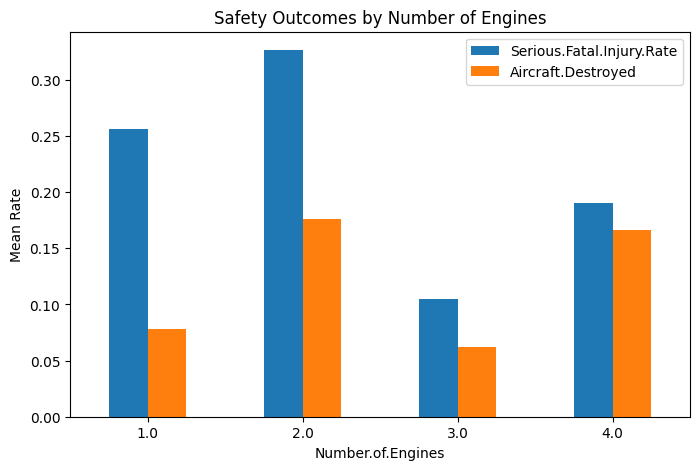

In [32]:
# Factor 2: Number of Engines
engines = df.groupby("Number.of.Engines").agg({
    "Serious.Fatal.Injury.Rate": "mean",
    "Aircraft.Destroyed": "mean"
})

print("Number of Engines:")
print(engines)

engines.plot(kind="bar", figsize=(8, 5))
plt.title("Safety Outcomes by Number of Engines")
plt.ylabel("Mean Rate")
plt.xticks(rotation=0)
plt.show()

The results show differences in safety outcomes across aircraft with different numbers of engines. In this dataset, two-engine aircraft had the highest mean serious/fatal injury rate at about 32.7%, while three-engine aircraft had the lowest rate at about 10.5%. The destruction rate was also highest for two-engine aircraft at about 17.6%, compared with about 6.3% for three-engine aircraft. However, these results should be interpreted together with the number of observations in each engine group, since groups with fewer accident records may produce less reliable averages. The analysis shows an association between the number of engines and accident outcomes, but it does not show that the number of engines directly causes these outcomes.